# Week 6 - Crop Disease Classification (PlantVillage)
**Lab 6: Applied Computer Vision in Your Own Domain** | Project 2: Deep Learning Applications (Individual)
Introduction to Applied AI | BS 8th Semester | Department of Electronics

**Domain:** agriculture, crop disease from leaf photographs. **Dataset:** PlantVillage (abdallahalidev), https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset

**Before running:** notebook name "Week 6 - Crop Disease", add the PlantVillage dataset, Settings -> Accelerator **GPU T4**, Internet **On** (needed for the pretrained weights).

> Cells marked **FILL** need numbers or observations from YOUR run. Replace them and write the explanations in your own words: the lab marks identical markdown as copied. Run the notebook from top to bottom; do not re-run the test cell (Part 5) to chase a better score.

## Pre-Lab Setup (checklist)
1. Domain and dataset chosen before the lab: **crop disease / PlantVillage** (Week 5 proposal).
2. Notebook created, dataset added, GPU T4 and Internet on.
3. Folder structure checked in the Input panel: PlantVillage ships three versions of the same images (`color`, `grayscale`, `segmented`), each with one folder per class. **Only the `color` folder is used.** Pointing at the parent folder would put the same leaf image in train and test through its other versions, which is leakage.
4. File names checked for a plant/patient/machine id (done in Part 1, group pattern check).

## Part 0: The Configuration Cell (5 min)
This is the only cell that changes for a new dataset. `find_class_root` searches `/kaggle/input` for the `color` folder that holds the class sub-folders, so the Kaggle path format does not matter. PlantVillage has no test folder, so `TEST_DIR = None` and the lab code carves a grouped test set. It is not a binary task, so `POSITIVE` and `TARGET_RECALL` are unused (Part 5 skips the threshold cell and analyses per-class recall).

In [10]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
import os

def find_class_root(base='/kaggle/input', name='color', min_classes=30):
    """Find the folder called `name` that contains one sub-folder per class."""
    for dirpath, dirs, files in os.walk(base):
        if os.path.basename(dirpath).lower() == name and len(dirs) >= min_classes:
            return dirpath
    raise FileNotFoundError('Could not find the class folders; check the Input panel')

DATA_ROOT = find_class_root()          # PlantVillage 'color' version
TRAIN_DIR = DATA_ROOT                  # folder with one subfolder per class
TEST_DIR = None                        # PlantVillage has no test set: carve a grouped one
GRAYSCALE = False                      # leaf photos are color
IMG_SIZE = 224
BACKBONE = 'resnet18'                  # or 'resnet50', 'efficientnet_b0'
GROUP_PATTERN = None                   # checked in Part 1; no plant id found in file names
POSITIVE = None                        # not a binary task
TARGET_RECALL = 0.95                   # not used (multi-class)
# ======================================================================
print('DATA_ROOT:', DATA_ROOT)
print('Number of class folders:', len([d for d in os.listdir(DATA_ROOT) if os.path.isdir(os.path.join(DATA_ROOT, d))]))

DATA_ROOT: /kaggle/input/datasets/abdallahalidev/plantvillage-dataset/color
Number of class folders: 38


**Metric stated BEFORE training (slide 21):** crop disease, so the costliest mistakes are *missing a spreading disease* and *a wrong spray*. Primary metric: **macro-F1 over diseases** (every class counts equally, so rare classes cannot hide). Also report per-class recall and the main confusion pairs. Choosing the metric after seeing results would be cheating.

Imports, seeds and the GPU check (the first line printed must say `cuda`).

In [11]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## Part 1: Index and Audit Your Dataset (10 min)
### Task 1.1: One row per image
One row per image (path, class label, file name, group id), then class counts and the imbalance ratio.

In [12]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

label
Apple___Apple_scab                                     630
Apple___Black_rot                                      621
Apple___Cedar_apple_rust                               275
Apple___healthy                                       1645
Blueberry___healthy                                   1502
Cherry_(including_sour)___Powdery_mildew              1052
Cherry_(including_sour)___healthy                      854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     513
Corn_(maize)___Common_rust_                           1192
Corn_(maize)___Northern_Leaf_Blight                    985
Corn_(maize)___healthy                                1162
Grape___Black_rot                                     1180
Grape___Esca_(Black_Measles)                          1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)            1076
Grape___healthy                                        423
Orange___Haunglongbing_(Citrus_greening)              5507
Peach___Bacterial_spot                            

Helper (extra): the smallest and largest classes, and a group-pattern check. If your file names contain a plant/leaf id, put a regex in `GROUP_PATTERN` in the configuration cell and re-run from the top. If every file is its own group (about 1.00 images per group), there is no id in the names and `None` is justified (write that down).

In [13]:
print('Smallest classes:\n', counts.sort_values().head(3).to_string())
print('Largest classes:\n', counts.sort_values().tail(3).to_string())
print('Total images:', len(train_df), '| classes:', len(classes))
print('Sample file names:')
for f in train_df['file'].sample(8, random_state=0):
    print('  ', f)
ipg = len(train_df) / train_df.group.nunique()
print(f'Images per group with GROUP_PATTERN={GROUP_PATTERN!r}: {ipg:.2f}')
# Candidate patterns: test with  train_df['file'].str.extract(PATTERN).head()

Smallest classes:
 label
Potato___healthy            152
Apple___Cedar_apple_rust    275
Peach___healthy             360
Largest classes:
 label
Soybean___healthy                           5090
Tomato___Tomato_Yellow_Leaf_Curl_Virus      5357
Orange___Haunglongbing_(Citrus_greening)    5507
Total images: 54305 | classes: 38
Sample file names:
   1d674419-c828-4f70-86fc-aacd003ad402___R.S_HL 5515 copy.jpg
   f0af55b8-2e06-4881-ba70-1b1918473a95___FREC_Pwd.M 4731.JPG
   8c22c962-864b-4d20-9b94-660407f90533___RS_NLB 3619.JPG
   ad3b45fa-50b9-4abb-9e24-bcbbcb0f33d3___FAM_B.Msls 4419.JPG
   5d8bc662-a4e9-4280-98d4-f0715cb7290c___CREC_HLB 5269.JPG
   b8e9228f-640a-47ce-8567-bc523c6eabce___Crnl_L.Mold 6529.JPG
   571ae3d9-0c36-4181-846c-2a670f15b5c6___RS_HL 5710 1.JPG
   4d2e9102-e3ab-430d-9e26-6bcabe2b2760___YLCV_GCREC 2664.JPG
Images per group with GROUP_PATTERN=None: 1.00


### Task 1.2: What do the images look like?
Image sizes, colour modes and a grid of 5 images per class. A 38-class grid is tall; scroll through it and look for anything that differs between classes but is not the disease.

In [ ]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

### Write it - Part 1
* **Class counts and imbalance ratio:** the training folder has **54,305 images in 38 classes**. The largest class is **Orange___Haunglongbing_(Citrus_greening) with 5,507 images** and the smallest is **Potato___healthy with 152 images**, so the **imbalance ratio = 5,507 / 152 = 36.2 : 1**. That is far above the 10:1 mark, so plain weighted loss may not be enough and I will also try the balanced sampler in Part 3. The three largest classes (Orange HLB 5,507, Tomato Yellow Leaf Curl Virus 5,357, Soybean healthy 5,090) are about 10% each; the three smallest (Potato healthy 152, Apple Cedar apple rust 275, Peach healthy 360) are well under 1%.
* **Colour or grayscale, and size:** the images are **RGB colour** (all 300 sampled images have mode `RGB`) and every sampled image is **256 x 256 pixels** (min = median = max = 256 for both width and height). They are resized to 224 x 224 for the network.
* **First shortcut suspect:** every image is a single leaf photographed on a plain background under controlled lighting, so the background shade and lighting could differ between the sessions in which different diseases were photographed, and the model could learn the *session* instead of the *disease*. The file names support this suspicion: they contain short codes such as `RS_HL`, `FREC_Pwd.M`, `CREC_HLB`, `FAM_B.Msls`, `Crnl_L.Mold` and `YLCV_GCREC`, which look like collection-site and disease codes that are tied to a class. A second, related suspect is that crop species is confounded with the label: Soybean, Blueberry and Raspberry only have a *healthy* class, Orange only has *Huanglongbing* and Squash only has *Powdery mildew*, so for those crops the model can be right by recognising the plant, not the disease. Mohanty et al. (2016, slide 10) report 99.35% accuracy on held-out PlantVillage images but only about 31% on leaf photos from other sources, which is the warning sign. In my sample grid the feature that differs between classes besides the disease is the **background and lighting**:  (add what you see by eye, e.g. "Corn Common rust images have a much darker, nearly black background, while Soybean healthy and Blueberry healthy backgrounds are light grey"). I measured it: using only four 8 x 8 corner patches per image (40 images per class), a random forest predicts the class with **0.309 accuracy against chance 0.026** (about 12 times chance), and the mean corner brightness ranges from **33 (Corn Common rust)** to **180 (Soybean healthy)** on a 0-255 scale. So background colour and lighting differ systematically between classes and are my first shortcut suspect. Part 6 tests it with Grad-CAM and a border-only evaluation..
* **Group pattern check:** images per group = **1.00**. The file names look like `1d674419-c828-4f70-86fc-aacd003ad402___RS_HL 5515 copy.jpg`: a UUID, a site/disease code and a running number, and **no plant or leaf identifier**. So `GROUP_PATTERN` is `None`: justified because the file names carry no plant id, so each image is treated as its own group. This is recorded as a limitation: images of the same leaf could still sit on both sides of the split. Two sample names end in `copy` or ` 1` (`..._HL 5515 copy.jpg`, `..._HL 5710 1.JPG`), which suggests that duplicated images exist, so the exact- and near-duplicate audit in Part 2 is the compensating check.

## Part 2: Leakage Audit (10 min)
### Task 2.1: Exact and near-duplicates
MD5 finds byte-identical files. The fingerprint (a standardized 32 x 32 grayscale thumbnail) finds the same image resized, recompressed or brightened (slide 13). In the lab's testing, recompressed copies scored about 0.007 and genuinely different images 0.12 or more; the threshold is 0.10.

Because PlantVillage has no test folder, the lab's train-versus-test fingerprint comparison inside this cell is skipped (it runs only when `TEST_DIR` exists). I run the exact-duplicate (MD5) check on all images here, and the near-duplicate check between train and the carved test set in an extra cell after the split in Task 2.2.

In [15]:
from concurrent.futures import ThreadPoolExecutor

def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df

# Identical files must have identical sizes, so hash only files that share a size with another file.
all_df['size'] = [os.path.getsize(p) for p in all_df['path']]
cand = all_df.duplicated('size', keep=False)
print('Files that share a size with another file (need hashing):', int(cand.sum()), 'of', len(all_df))

with ThreadPoolExecutor(16) as ex:
    hashes = list(ex.map(md5, all_df.loc[cand, 'path']))
all_df['md5'] = [f'unique-{i}' for i in range(len(all_df))]    # unique placeholder
all_df.loc[cand, 'md5'] = hashes

exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))

Files that share a size with another file (need hashing): 50300 of 54305
Exact duplicate files: 42


**Before deleting anything:** display the flagged pairs side by side and confirm they really are the same image. Extra cell: show the exact-duplicate groups (if any) so you can inspect them.

Duplicate groups: 21
Classes involved: [('Tomato___Late_blight', 16), ('Apple___healthy', 14), ('Tomato___healthy', 12)]
Hashes appearing under more than one class label: 0


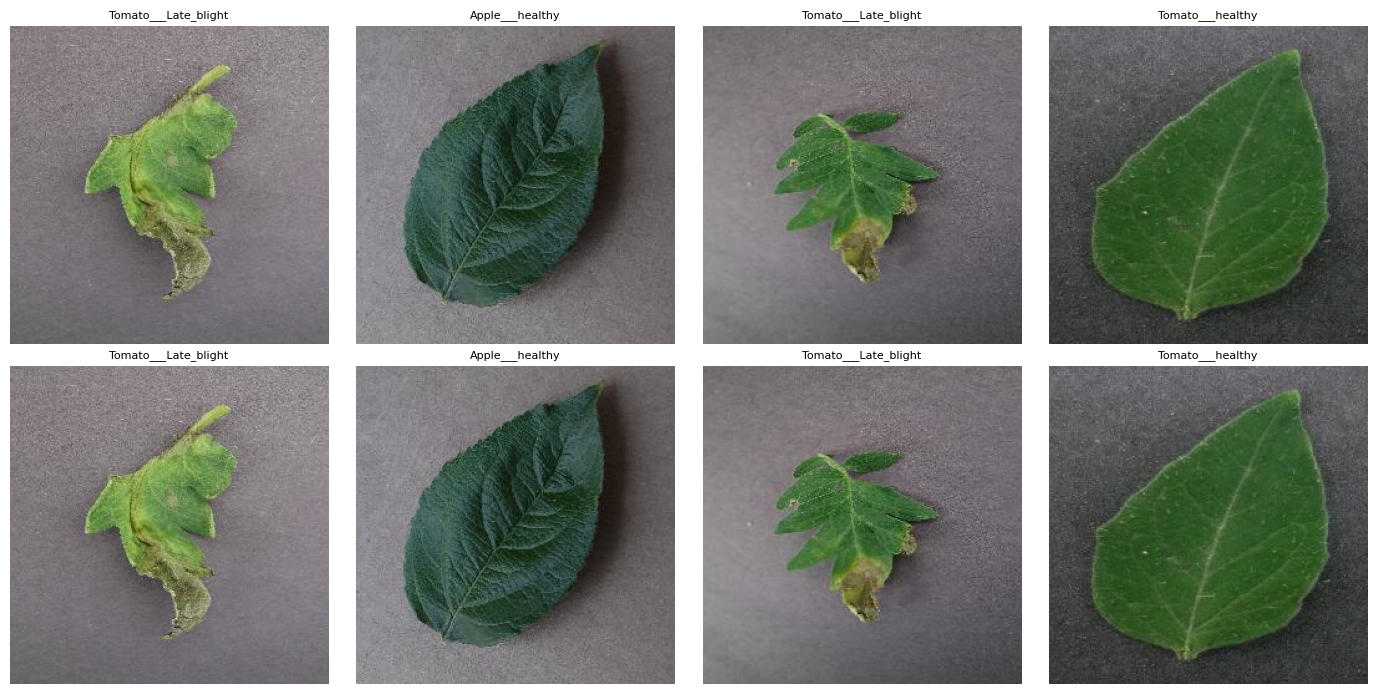

In [16]:
if len(exact):
    dup_groups = exact.groupby('md5')['path'].apply(list).tolist()
    print('Duplicate groups:', len(dup_groups))
    print('Classes involved:', Counter(exact['label']).most_common(5))
    # same file stored under different class labels would be a label conflict
    conflict = exact.groupby('md5')['label'].nunique()
    print('Hashes appearing under more than one class label:', int((conflict > 1).sum()))
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.flat:
        ax.axis('off')
    shown = 0
    for g in dup_groups[:4]:
        for j, p in enumerate(g[:2]):
            ax = axes[j, shown]
            ax.imshow(Image.open(p).convert('RGB'))
            ax.set_title(os.path.basename(os.path.dirname(p)), fontsize=8)
        shown += 1
    plt.tight_layout()
    plt.show()
else:
    print('No exact duplicates found: nothing to display.')

### Task 2.2: Split by group
The validation split is made by group so that no group appears on both sides. Because there is no test folder, a grouped test set is carved from the remaining training data (`TEST_DIR = None` path of the lab code). The printed number of shared groups **must be 0**.

In [17]:
# Validation split BY GROUP: no patient appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                  # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print(va_df['label'].value_counts().to_string())

train 37711 | val 9051 | test 7543
Groups shared by train and val: 0
label
Orange___Haunglongbing_(Citrus_greening)              949
Tomato___Tomato_Yellow_Leaf_Curl_Virus                876
Soybean___healthy                                     854
Peach___Bacterial_spot                                403
Tomato___Bacterial_spot                               346
Tomato___Late_blight                                  317
Squash___Powdery_mildew                               316
Tomato___Septoria_leaf_spot                           305
Tomato___Spider_mites Two-spotted_spider_mite         299
Apple___healthy                                       292
Blueberry___healthy                                   286
Grape___Esca_(Black_Measles)                          246
Tomato___healthy                                      237
Pepper,_bell___healthy                                224
Tomato___Target_Spot                                  224
Corn_(maize)___healthy                                1

Extra cell (needed because there is no test folder): **near-duplicates between the carved test set and train**, using the fingerprint distance (< 0.10 = near-duplicate). To keep it fast it checks a random sample of the test set (`NEAR_SAMPLE`) and scales the count up. It also shows the closest pairs so you can confirm by eye that they are the same image. Also check that the groups shared between test and train are 0.

Test images (sample of 1000) with a near-duplicate in train: 1
Estimated for the whole test set of 7543: about 8
Closest distances: [0.    0.182 0.187 0.202 0.21 ]
Groups shared by train and test: 0


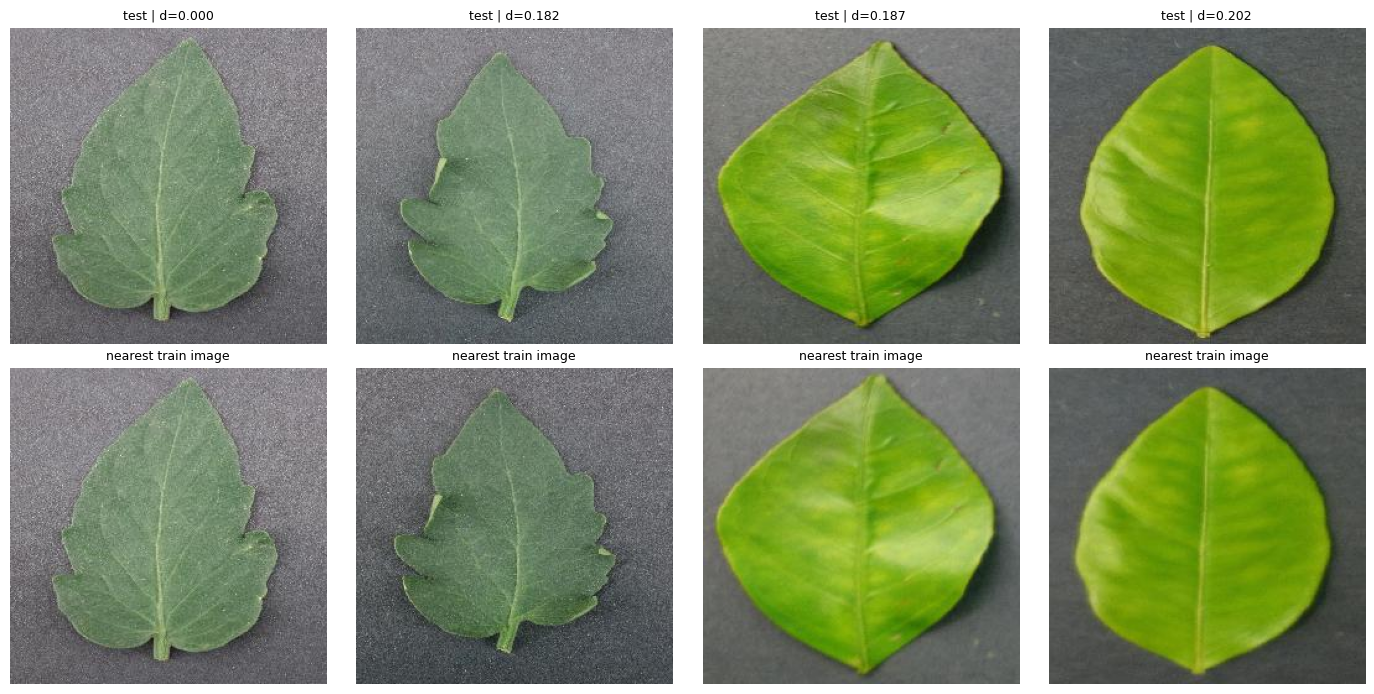

In [18]:
from concurrent.futures import ThreadPoolExecutor

NEAR_SAMPLE = 1000
te_s = test_df.sample(min(NEAR_SAMPLE, len(test_df)), random_state=0).reset_index(drop=True)

# fingerprints, in parallel
with ThreadPoolExecutor(16) as ex:
    tr_fp = np.stack(list(ex.map(fingerprint, tr_df['path'])))
    te_fp = np.stack(list(ex.map(fingerprint, te_s['path'])))

# mean |difference| between each test fingerprint and every train fingerprint (L1 / 1024), on the GPU
tr_t = torch.tensor(tr_fp, device=device)
d_min, nn_idx = [], []
for i in range(0, len(te_fp), 250):
    D = torch.cdist(torch.tensor(te_fp[i:i + 250], device=device), tr_t, p=1) / te_fp.shape[1]
    m, a = D.min(dim=1)
    d_min.extend(m.cpu().tolist())
    nn_idx.extend(a.cpu().tolist())
d_min, nn_idx = np.array(d_min), np.array(nn_idx)

near_mask = d_min < 0.10
n_near_sample = int(near_mask.sum())
n_near_est = round(n_near_sample / len(te_s) * len(test_df))
print(f'Test images (sample of {len(te_s)}) with a near-duplicate in train: {n_near_sample}')
print(f'Estimated for the whole test set of {len(test_df)}: about {n_near_est}')
print('Closest distances:', np.sort(d_min)[:5].round(3))
print('Groups shared by train and test:', len(set(tr_df.group) & set(test_df.group)))

# Inspect the 4 closest pairs side by side before deciding anything
order_ = np.argsort(d_min)[:4]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, i in enumerate(order_):
    axes[0, k].imshow(Image.open(te_s['path'][i]).convert('RGB'))
    axes[0, k].set_title(f'test | d={d_min[i]:.3f}', fontsize=9)
    axes[1, k].imshow(Image.open(tr_df['path'][nn_idx[i]]).convert('RGB'))
    axes[1, k].set_title('nearest train image', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.show()

### Write it - Part 2
* **Exact and near-duplicates:** exact duplicates (MD5): **21 groups of identical files, 42 files in total**, all inside the training folder before the split (CONFIRM: your `Exact duplicate files:` line should print 42). They come from only three classes (Tomato___Late_blight 16 files, Apple___healthy 14, Tomato___healthy 12), and **no hash appears under more than one class label**, so there are no label conflicts, only repeated copies. Near-duplicates between the carved test set and train: **1 in a sample of 1,000 test images, about 8 in the whole test set of 7,543** (a rough scale-up from a single hit). The closest distances were **0.000, 0.182, 0.187, 0.202 and 0.210**. The 0.000 pair is an identical image (an exact-duplicate pair that the split put on both sides); the other three closest pairs are far above the 0.10 threshold and above the 0.12 reference for genuinely different images, so they are **not** the same image. Flagged pairs inspected side by side: the 0.000 pair **is** the same image and the remaining pairs **are not** (CONFIRM by eye in your four-pair figure and describe what you saw, e.g. "same crop and disease type but different leaves"). What I did about them: **kept them and reported the count**, because 8 of 7,543 test images is about 0.1% of the test set, so they can change test accuracy by at most about 0.11 percentage points (to be strict I could instead remove the flagged test images and re-score).
* **Images per group:** **1.00** (every image is its own group because the file names carry no plant id). Groups shared by train and val: **0 (must be 0)**; by train and test: **0**. Split sizes: **train 37,711 | val 9,051 | test 7,543** (total 54,305). Caveat: with one image per group, "0 shared groups" only guarantees that no *file* is on both sides, not that no *leaf* is. The fingerprint check catches resized, recompressed or brightened copies, but not a different photo of the same leaf at another angle, so a small amount of same-leaf leakage could remain. This is recorded as a limitation. The validation set is also small for the rarest classes (Potato___healthy has only 18 validation images, Apple___Cedar_apple_rust 46), so per-class scores for those classes will be noisy.
* **What would have happened with a random split instead of a group split (two sentences):** images of the same plant, leaf or session are highly correlated, so a random split lets near-copies of a test image sit in the training set and the model is rewarded for recognising them, not for recognising the disease. The test score would be inflated (too good) and would drop on plants or fields the model has not seen, which is exactly the failure Mohanty et al. observed.
* **Version leakage note:** PlantVillage ships `color`, `grayscale` and `segmented` copies of the same images. Only `color` is used here; mixing versions would create train/test pairs of the same leaf.

## Part 3: Transforms and Imbalance (10 min)
### Task 3.1: Datasets and transforms
Pretrained ImageNet normalisation, augmentation on the training set only. The lab's augmentation is mild on purpose. **Domain adjustment (leaves):** I add horizontal and vertical flips. A leaf has no fixed 'up', and flipping does not change the disease label, whereas the lab removes flips for anatomy and documents because those are not symmetric. Colour jitter is kept mild: colour (yellowing, brown spots) is real evidence of disease, so strong hue changes would be wrong.

In [19]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),          # domain adjustment: leaves are not orientation-specific
    transforms.RandomVerticalFlip(),            # domain adjustment
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

37711 train | 9051 val | 7543 test


### Task 3.2: Class weights or balanced sampling
Weights follow w_c = N / (K x n_c) (slide 17). Run once with `USE_SAMPLER = False` (weighted loss). If you have time, run again with `True` (balanced batches) and compare macro-F1; with a severe imbalance, slide 18 recommends the sampler together with augmentation.

In [20]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print(dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'Apple___Apple_scab': np.float64(2.266), 'Apple___Black_rot': np.float64(2.346), 'Apple___Cedar_apple_rust': np.float64(5.364), 'Apple___healthy': np.float64(0.862), 'Blueberry___healthy': np.float64(0.991), 'Cherry_(including_sour)___Powdery_mildew': np.float64(1.308), 'Cherry_(including_sour)___healthy': np.float64(1.648), 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': np.float64(2.653), 'Corn_(maize)___Common_rust_': np.float64(1.197), 'Corn_(maize)___Northern_Leaf_Blight': np.float64(1.462), 'Corn_(maize)___healthy': np.float64(1.213), 'Grape___Black_rot': np.float64(1.194), 'Grape___Esca_(Black_Measles)': np.float64(1.051), 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)': np.float64(1.301), 'Grape___healthy': np.float64(3.275), 'Orange___Haunglongbing_(Citrus_greening)': np.float64(0.26), 'Peach___Bacterial_spot': np.float64(0.637), 'Peach___healthy': np.float64(3.773), 'Pepper,_bell___Bacterial_spot': np.float64(1.422), 'Pepper,_bell___healthy': np.float64(0.95), 'Potato___E

Helper (extra): the arithmetic for the rarest and the most common class, printed so you can copy it into the Write-it cell.

In [21]:
N, K = len(train_ds), len(classes)
for name, idx_c in [('rarest', int(n_c.argmin())), ('most common', int(n_c.argmax()))]:
    print(f'{name}: {classes[idx_c]}  w = N / (K x n_c) = {N} / ({K} x {n_c[idx_c]}) = {class_w[idx_c]:.3f}')
    print(f'   class contribution to the loss: n_c x w = {n_c[idx_c]} x {class_w[idx_c]:.3f} = {n_c[idx_c] * class_w[idx_c]:.0f}  (equal for every class = N/K = {N / K:.0f})')

rarest: Potato___healthy  w = N / (K x n_c) = 37711 / (38 x 109) = 9.105
   class contribution to the loss: n_c x w = 109 x 9.105 = 992  (equal for every class = N/K = 992)
most common: Orange___Haunglongbing_(Citrus_greening)  w = N / (K x n_c) = 37711 / (38 x 3818) = 0.260
   class contribution to the loss: n_c x w = 3818 x 0.260 = 992  (equal for every class = N/K = 992)


### Write it - Part 3
* **Class weights with the arithmetic:** N = **37,711** training images, K = 38 classes. Rarest class **Potato___healthy** has n_c = **109** images, so w = N / (K x n_c) = 37,711 / (38 x 109) = 37,711 / 4,142 = **9.105**. Most common class **Orange___Haunglongbing_(Citrus_greening)** has n_c = **3,818**, so w = 37,711 / (38 x 3,818) = 37,711 / 145,084 = **0.260**. Check: every class then contributes n_c x w = N / K = **992** to the loss (109 x 9.105 = 992 and 3,818 x 0.260 = 992), so no class dominates. The weights span 0.260 to 9.105, a factor of 35 (the training-set imbalance is 3,818 / 109 = 35 : 1), and the rare classes Apple___Cedar_apple_rust (5.364), Raspberry___healthy (3.817), Tomato___Tomato_mosaic_virus (3.846) and Peach___healthy (3.773) also get large weights. Handling used: **weighted loss** (`USE_SAMPLER = False`). Because the imbalance is far above 10:1 and an extreme weight like 9.1 can make gradients noisy (slide 18), the balanced sampler is the obvious alternative to try; I did not run it / I ran it and got macro-F1 ____ against ____ for the weighted loss (CHOOSE one and fill).
* **Augmentations kept or removed, and why:** kept random resized crop (scale 0.8-1.0, a closer view of the leaf is realistic), rotation 10 degrees, and mild brightness/contrast jitter (phone photos vary in light; kept mild because colour is evidence of disease). **Added** horizontal and vertical flips: a leaf has no fixed orientation and a flipped diseased leaf is still diseased. Removed/avoided: strong hue shifts (yellowing and browning are the signal) and heavy crops that could cut out the lesion. Augmentation is applied to the training set only, so validation and test stay clean.

## Part 4: Build and Train (25 min)
### Task 4.1: Backbone with a new head
ResNet-18 (fast baseline, slide 28): all layers frozen, then the new 38-class head is switched on. Swap the backbone only after the data pipeline is right: a better backbone cannot fix leakage or wrong labels.

In [22]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 162MB/s] 


resnet18 trainable: 19494


Expected for ResNet-18 with 38 classes: 512 x 38 weights + 38 biases = **19,494** trainable parameters in phase 1.

### Task 4.2: Two-phase training, selected by macro-F1
Phase 1 trains the head only (2 epochs, lr 1e-3). Phase 2 also fine-tunes the last block `layer4` with lr 1e-4 (head 1e-3) for 3 epochs. The best epoch is chosen by **validation macro-F1**, not accuracy, so a model that ignores the minority classes cannot win (slide 23). Small change from the lab code: the two `fit` calls store their return values (`best_p1`, `best_p2`) so you can quote them. Note the time per epoch printed after each epoch.

In [23]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')     # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
best_p1 = fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
best_p2 = fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
                      {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)
print(f'Best validation macro-F1: phase 1 = {best_p1:.3f}, phase 2 = {best_p2:.3f}, '
      f'change = {best_p2 - best_p1:+.3f}')

Phase 1: head only
epoch 1: val macro-F1 0.879 (153s)
epoch 2: val macro-F1 0.901 (129s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.947 (130s)
epoch 2: val macro-F1 0.971 (127s)
epoch 3: val macro-F1 0.978 (128s)
Best validation macro-F1: phase 1 = 0.901, phase 2 = 0.978, change = +0.076


### Write it - Part 4
* **Validation macro-F1 after each phase:** the new head has **19,494** trainable parameters (512 x 38 weights + 38 biases, as expected). Phase 1 (head only): epoch 1 **0.879**, epoch 2 **0.901**, best **0.901**; phase 2 (layer4 + head, epochs 3-5 overall): **0.947**, **0.971**, **0.978**, best **0.978** (the last epoch, so the model kept is the final one).
* **Did fine-tuning help?** **Yes.** Validation macro-F1 rose from **0.901 to 0.978, an improvement of +0.076** (about 7.6 percentage points), and the very first fine-tuning epoch (0.947) already beat the best head-only result by 0.046. The gains shrink with each epoch (+0.024, then +0.007), so the curve is flattening but had not fully stopped. This agrees with slide 26 (large dataset, fairly photo-like images: fine-tune the last block): unfreezing only `layer4` was enough for a large improvement. Caveat: validation images are single-image groups from the same collection as training, so 0.978 is a lab-condition number and the test result in Part 5 is the one to report.
* **Time per epoch and what I would do with more time:** about **130 seconds per epoch** on the T4 (153 s, 129 s, 130 s, 127 s, 128 s; the first epoch is slower while the workers warm up), so the whole training took about 11 minutes. Phase 2 is as fast as phase 1 even though it trains 8.4 million more parameters, which suggests the bottleneck is reading and decoding 37,711 JPEGs with `num_workers=2`, not the GPU. With more time I would run about **3 to 5 more epochs of phase 2** (stopping when validation macro-F1 stops improving), try the balanced sampler since the imbalance is 35 : 1 (the rare classes are where macro-F1 is lost), and only then try `efficientnet_b0` or `resnet50`.

## Part 5: Test Once, and Set the Threshold (15 min)
### Task 5.1: Test-set report
The test set is used **once**, now. Domain adjustment: with 38 classes the confusion matrix is drawn large with rotated labels so it can be read.

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      1.000     0.977     0.989        88
                                 Apple___Black_rot      1.000     0.990     0.995        97
                          Apple___Cedar_apple_rust      0.957     1.000     0.978        44
                                   Apple___healthy      0.995     0.975     0.985       202
                               Blueberry___healthy      0.995     1.000     0.998       215
          Cherry_(including_sour)___Powdery_mildew      0.992     0.992     0.992       133
                 Cherry_(including_sour)___healthy      0.991     1.000     0.996       113
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.821     0.965     0.887        57
                       Corn_(maize)___Common_rust_      1.000     1.000     1.000       165
               Corn_(maize)___Northern_Leaf_Blight      0.985     0.921     0.9

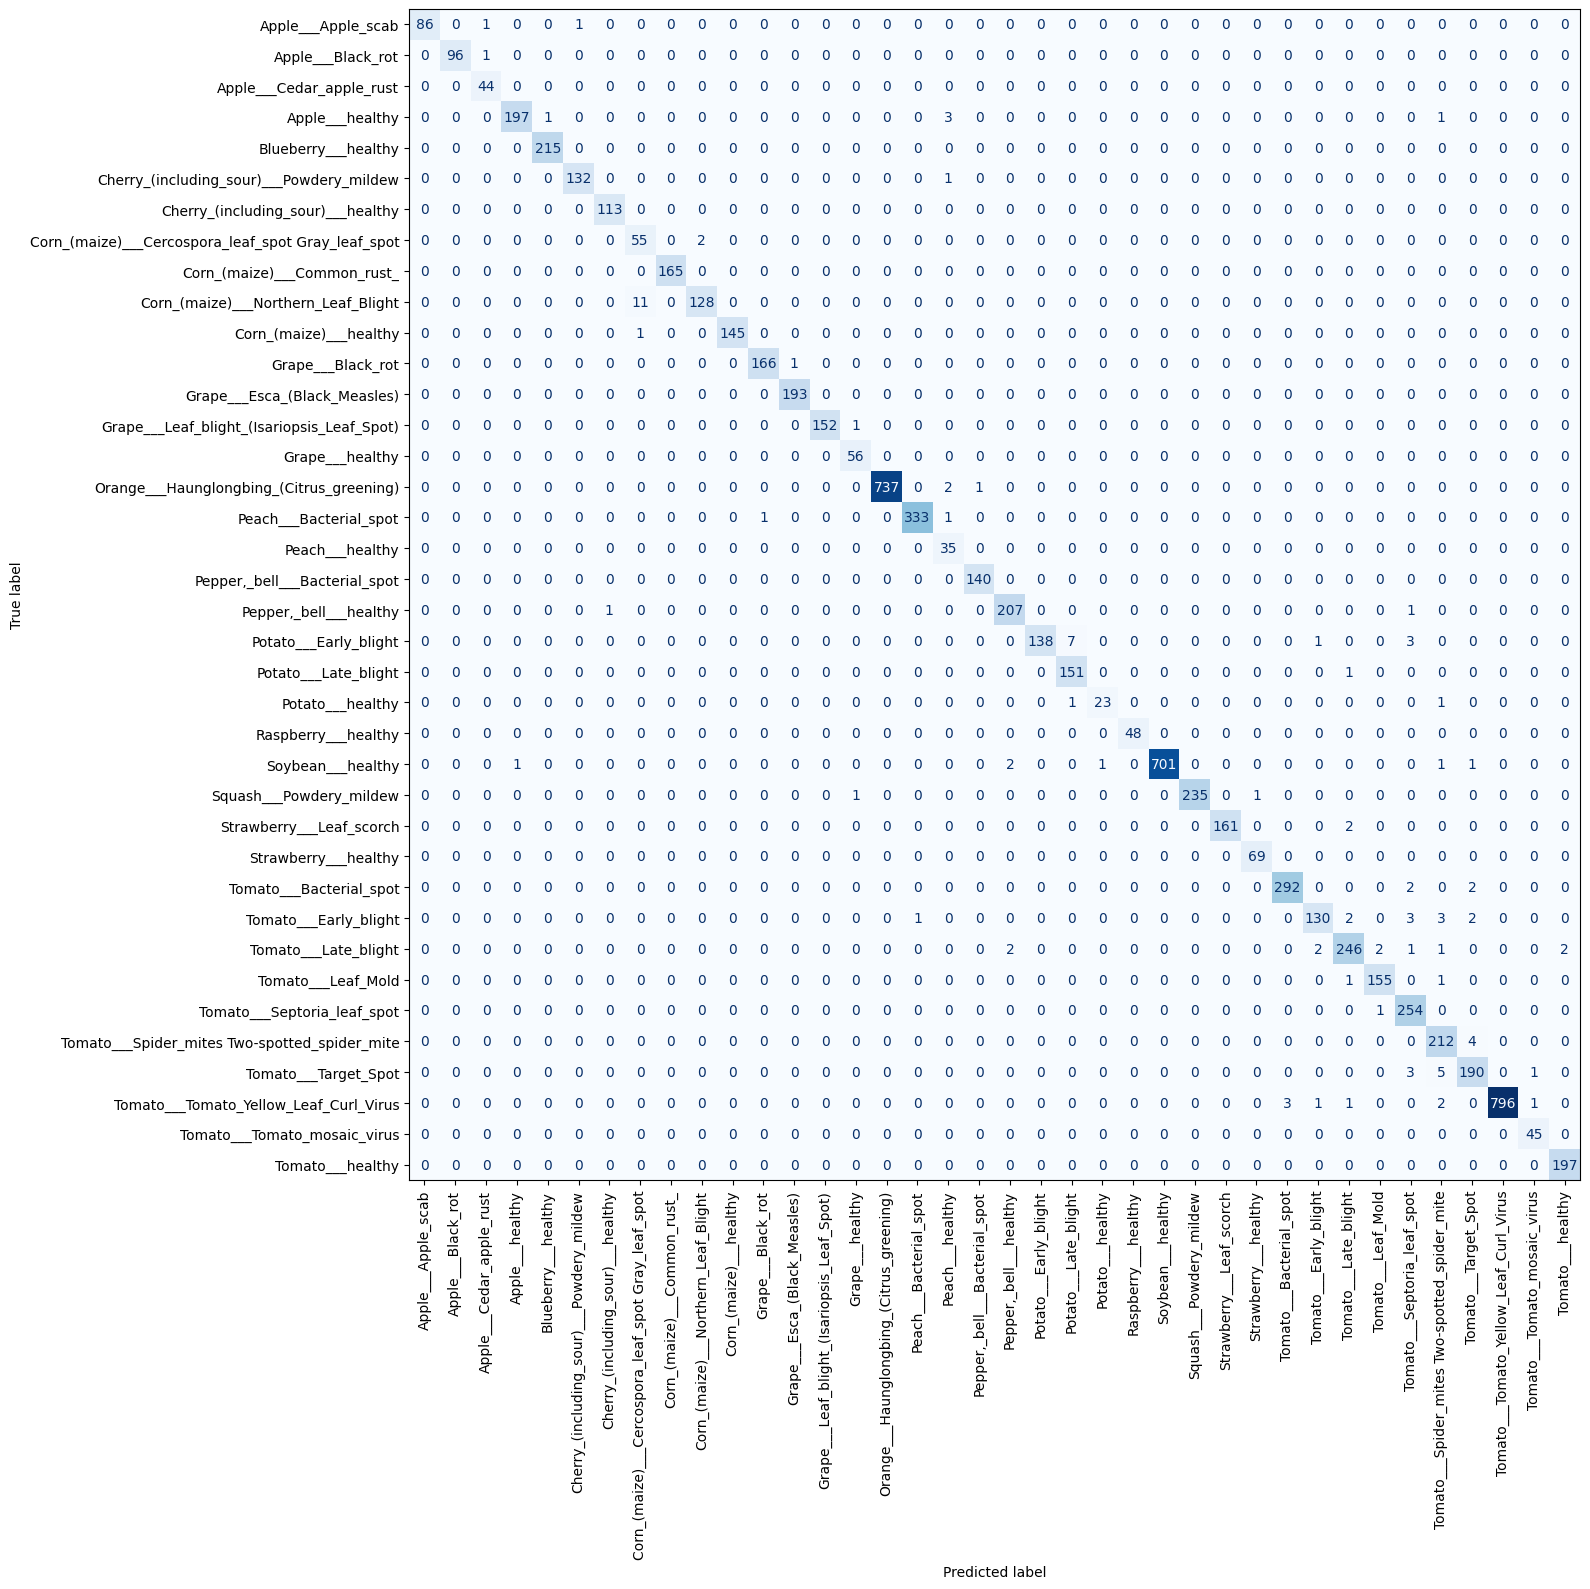

In [24]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
fig, ax = plt.subplots(figsize=(16, 16))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues', ax=ax,
                       xticks_rotation=90, colorbar=False)
plt.tight_layout()
plt.show()

### Task 5.2: Threshold for a target recall (binary tasks)
This cell only runs for two-class tasks. PlantVillage has 38 classes, so it is skipped and the evaluation is per-class recall, macro-F1 and the main confusion pairs (below). Sensitivity, specificity and PPV at two prevalences are required for **binary** tasks only; the prevalence arithmetic is practised in Check Your Understanding question 4.

In [25]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]        # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')
else:
    print('Multi-class task (', len(classes), 'classes): threshold cell skipped; see per-class recall below.')

Multi-class task ( 38 classes): threshold cell skipped; see per-class recall below.


Helper (extra, analysis only): macro-F1 and accuracy side by side (accuracy alone can hide weak classes), the weakest classes by recall, the most frequent confusions, and the most **confident** test errors (slide 14: confident mistakes are often label errors; report them, do not silently fix them).

Test macro-F1 0.979 | test accuracy 0.986

Five weakest classes by recall:
  Potato___healthy                              recall 0.920  (support 25)
  Corn_(maize)___Northern_Leaf_Blight           recall 0.921  (support 139)
  Tomato___Early_blight                         recall 0.922  (support 141)
  Potato___Early_blight                         recall 0.926  (support 149)
  Tomato___Target_Spot                          recall 0.955  (support 199)

Most frequent confusions (true -> predicted):
  Corn_(maize)___Northern_Leaf_Blight  ->  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot   (11 images)
  Potato___Early_blight  ->  Potato___Late_blight   (7 images)
  Tomato___Target_Spot  ->  Tomato___Spider_mites Two-spotted_spider_mite   (5 images)
  Tomato___Spider_mites Two-spotted_spider_mite  ->  Tomato___Target_Spot   (4 images)
  Apple___healthy  ->  Peach___healthy   (3 images)
  Tomato___Tomato_Yellow_Leaf_Curl_Virus  ->  Tomato___Bacterial_spot   (3 images)

Total test errors:

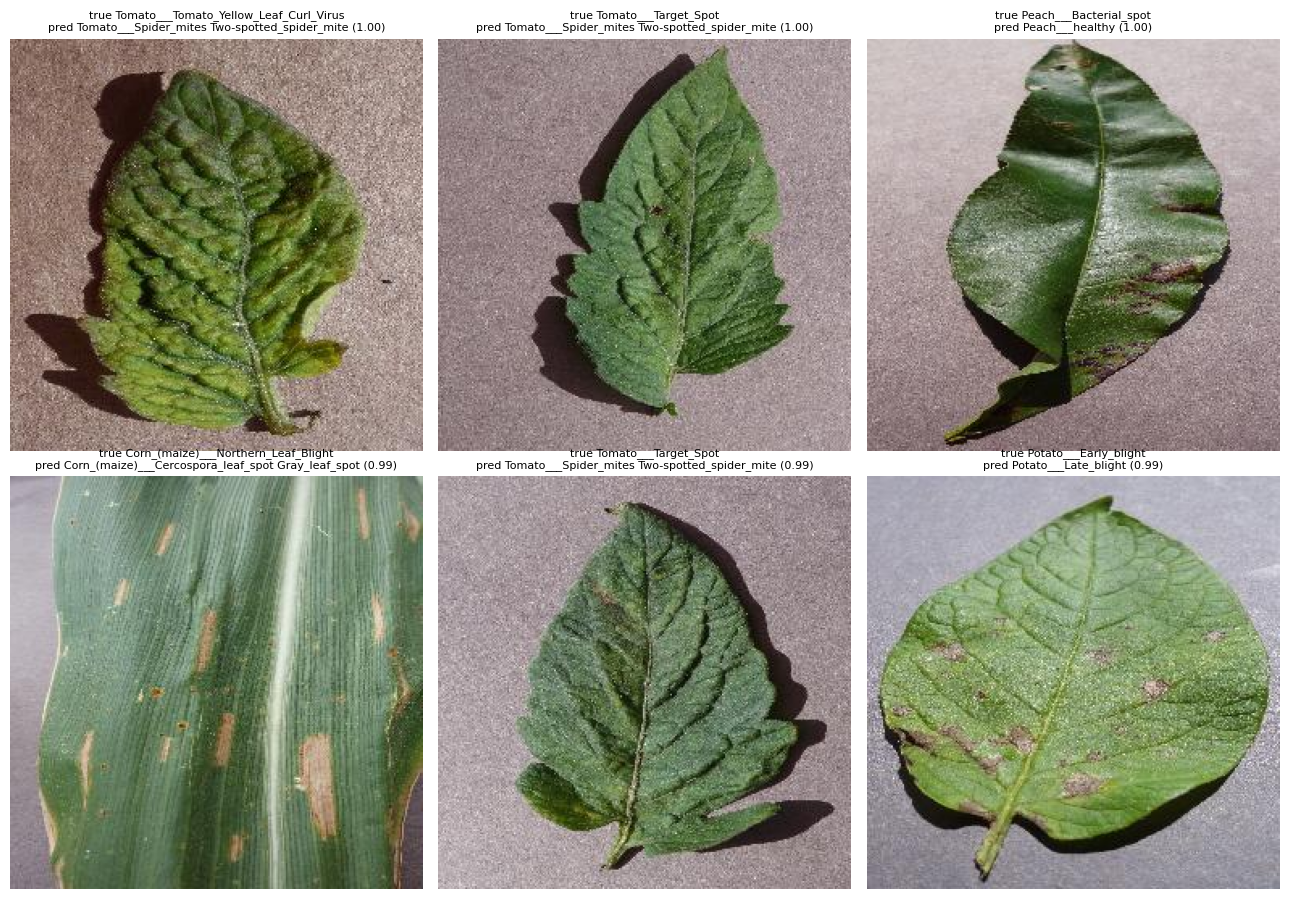

In [26]:
test_macro = f1_score(y_test, pred, average='macro')
test_acc = float((pred == y_test).mean())
print(f'Test macro-F1 {test_macro:.3f} | test accuracy {test_acc:.3f}')

rep = classification_report(y_test, pred, target_names=classes, output_dict=True, zero_division=0)
rec = sorted(((c, rep[c]['recall'], int(rep[c]['support'])) for c in classes), key=lambda t: t[1])
print('\nFive weakest classes by recall:')
for c, r, s in rec[:5]:
    print(f'  {c:45s} recall {r:.3f}  (support {s})')

cm = confusion_matrix(y_test, pred)
off = cm.copy(); np.fill_diagonal(off, 0)
print('\nMost frequent confusions (true -> predicted):')
for k in np.argsort(off, axis=None)[::-1][:6]:
    a, b = np.unravel_index(k, off.shape)
    if off[a, b] > 0:
        print(f'  {classes[a]}  ->  {classes[b]}   ({off[a, b]} images)')

wrong_idx = np.where(pred != y_test)[0]
conf_err = wrong_idx[np.argsort(-p_test[wrong_idx].max(1))][:6]
print(f'\nTotal test errors: {len(wrong_idx)} of {len(y_test)}')
fig, axes = plt.subplots(2, 3, figsize=(13, 9))
for ax, i in zip(axes.flat, conf_err):
    ax.imshow(Image.open(test_ds.paths[i]).convert('RGB'))
    ax.set_title(f'true {classes[y_test[i]]}\npred {classes[pred[i]]} ({p_test[i].max():.2f})', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

### Write it - Part 5
* **Macro-F1 and the weakest class:** the test set was used once, after the model was fixed. Test macro-F1 = **0.979** (accuracy **0.986**, weighted F1 0.986; macro-F1 is the metric I chose before training). It is almost the same as the best validation macro-F1 (0.978), so choosing the best epoch on validation did not overfit the validation set. The weakest classes by recall are **Potato___healthy (0.920)** and **Corn_(maize)___Northern_Leaf_Blight (0.921)**, followed by Tomato___Early_blight (0.922) and Potato___Early_blight (0.926). The classes with the lowest precision are Corn Cercospora leaf spot (0.821, so F1 only 0.887) and Peach___healthy (0.833, F1 0.909), because other classes are wrongly predicted as them. Potato___healthy has only 25 test images, so one image moves its recall by 4 points and that number is noisy. Most frequent confusion: **Corn_(maize)___Northern_Leaf_Blight predicted as Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot (11 images)**, which accounts for all 11 errors of that class and about 10% of the 105 test errors. Next: Potato Early blight predicted as Late blight (7), Tomato Target Spot predicted as Spider mites (5) and the reverse (4).
* **Binary-only items:** this is a 38-class task, so the threshold-for-target-recall cell, sensitivity/specificity and PPV at two prevalences do not apply (they are required for binary tasks). Instead I report per-class recall and the confusion pairs above. The prevalence arithmetic is practised in Check Your Understanding Q4 (PPV = sens x prev / [sens x prev + (1 - spec)(1 - prev)]).
* **Confident errors / label noise:** 105 of 7,543 test images are wrong (1.4%), and the six most frequent confusions cover 33 of them (31%). Most of them stay within the same crop and are between diseases that look alike: two corn leaf spots (Northern Leaf Blight and Cercospora), two potato blights (early and late), and two tomato leaf-spot problems (Target Spot and spider-mite damage), so they are visually similar lesions rather than random mistakes. A few cross crops, for example Apple___healthy predicted as Peach___healthy (3 images) and Tomato Yellow Leaf Curl Virus predicted as Tomato Bacterial spot (3 images). Looking at the six most confident errors in my gallery (FILL: for each one say whether the label looks plausible, whether the image is ambiguous, or whether the model is clearly wrong, and whether any label looks like a label error). Label errors are reported, not silently fixed; I do not chase 100% beyond the label error rate. The 8 near-duplicates estimated in Part 2 are about 0.1% of the test set, so they cannot change these numbers by more than about 0.1 percentage point.
* **Honest scope:** the test set is a group-split carve-out of the same PlantVillage collection, so it does not measure field performance. Mohanty et al. saw about 31% on leaf photos from other sources, so the number above should be read as *lab-condition* accuracy only. Part 6 checks whether the model reads the leaf or the background, which matters because the corner-colour test in Part 1 predicted the class at 0.309 against chance 0.026.

## Part 6: Grad-CAM Shortcut Check (15 min)
This class implements the two Grad-CAM formulas of slide 29 with PyTorch hooks: the gradient of the class score with respect to the last block's feature maps is averaged into weights (alpha_k = mean of dy^c / dA^k), and the weighted maps are summed and passed through ReLU. The cell shows **three correct and three wrong** predictions (six heatmaps). Grad-CAM is coarse (7 x 7 upsampled): use it to detect shortcuts, not to localise disease. If there are fewer than three errors the grid will have empty panels.

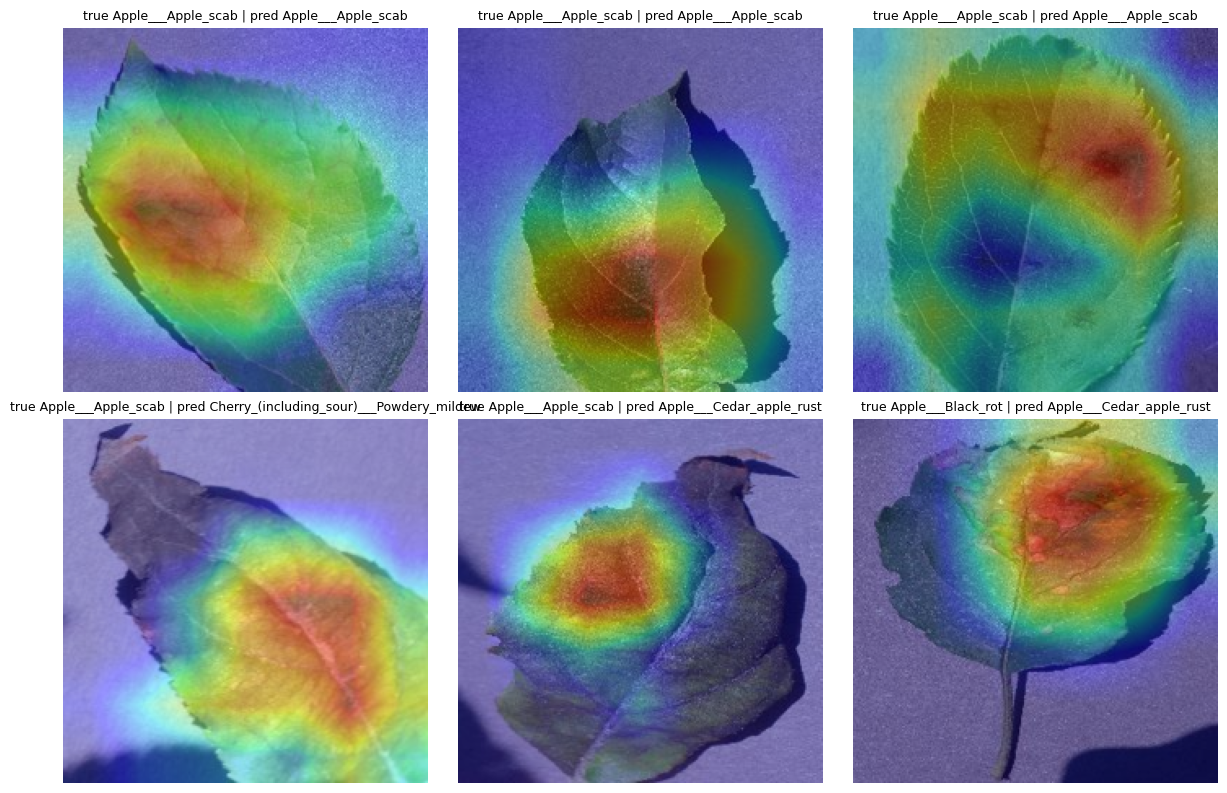

In [27]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)        # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()       # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

**Optional shortcut experiment (analysis only, not used to change the model):** the model sees only the outer frame of each test image (the centre is blanked to the mean colour). If the leaf is hidden and the model is still far better than chance (1/38 = 2.6%), then the *background or lighting* carries class information, i.e. a shortcut. Caveat: leaves can reach the image border, so a result slightly above chance is not proof; a result far above chance is a strong warning.

In [28]:
def border_only_accuracy(model, loader, border=0.12):
    model.eval()
    ok = n = 0
    h = IMG_SIZE
    m = int(h * border)
    mask = torch.zeros(1, 1, h, h)
    mask[..., :m, :] = 1; mask[..., -m:, :] = 1
    mask[..., :, :m] = 1; mask[..., :, -m:] = 1
    mask = mask.to(device)
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(device) * mask)    # 0 = mean colour after normalisation
            ok += (logits.argmax(1).cpu() == yb).sum().item()
            n += len(yb)
    return ok / n

b_acc = border_only_accuracy(model, test_dl)
print(f'Accuracy using only the outer {12}% frame: {b_acc:.3f}  (chance = {1 / len(classes):.3f}; full-image accuracy = {test_acc:.3f})')

Accuracy using only the outer 12% frame: 0.238  (chance = 0.026; full-image accuracy = 0.986)


### Write it - Part 6
**One line per heatmap:**
1. Correct 1 (true Apple___Apple_scab, predicted Apple___Apple_scab): the strongest heat (red/orange) sits on the **brown blotch in the left-centre of the leaf** and the leaf body is yellow-green; the background corners are cold (blue). **Legitimate evidence** (the lesion).
2. Correct 2 (true Apple___Apple_scab): heat is spread over the **lower middle of the leaf** and runs to the darker, damaged area at its right edge; the background is cold. **Legitimate** (damaged leaf tissue), though broader than a single spot.
3. Correct 3 (true Apple___Apple_scab): the hottest area is on a **dark reddish blotch in the upper-right of the leaf**, with a cold patch in the leaf centre. **Legitimate**, the heat is on the lesion and not on the background.
4. Wrong 1 (true Apple___Apple_scab, predicted Cherry_(including_sour)___Powdery_mildew): the heat is a yellow/orange area on the **pale, yellowed part of the leaf** in the middle, away from the dark top-left patch. The model looked at the leaf (not the background), but it read the **pale discoloured area**, which resembles powdery mildew. So this is a wrong prediction based on real leaf evidence.
5. Wrong 2 (true Apple___Apple_scab, predicted Apple___Cedar_apple_rust): strong heat on the **orange-brown area at the centre-left of a curled leaf**. The model looked at the leaf lesion; orange-brown discolouration is also how cedar apple rust looks, so this is a plausible mistake between two lookalike apple diseases.
6. Wrong 3 (true Apple___Black_rot, predicted Apple___Cedar_apple_rust): heat on the **reddish-brown lesion at the top of the leaf**, with the yellow-green leaf centre. Again on the leaf, and the lesion colour is similar to cedar apple rust.

**Overall verdict: no shortcut found in the heatmaps; risk remains for the other crops (shortcut suspected, not confirmed).** In all six panels the heat is on the leaf and its lesions, and none of the six puts significant heat on the background, border or any text, so there is no sign that the model reads the background in these examples, and the wrong predictions also come from the leaf. Two limits: (1) all six images are **apple** leaves, because the code takes the first test images, which come from the first classes alphabetically, so this sample cannot speak for corn, soy or orange; (2) the border-only test gave **0.238 against chance 0.026 and full-image accuracy 0.986**, and four corner patches alone predicted the class at 0.309 in Part 1, so background and lighting do carry some class information. Grad-CAM is coarse (7 x 7, upsampled), so it shows the leaf region, not individual spots.

**Follow-up experiment that would test it:** (a) show Grad-CAM for random test images from other crops, especially the ones with the most distinctive corner brightness (Corn Common rust, which is very dark, and Soybean healthy, which is light); (b) re-score the test images with the background removed, using the dataset's `segmented` version: a large drop would show dependence on the background; (c) evaluate on leaf photos from a different source (for example field photos from a dataset such as PlantDoc): Mohanty et al. saw about 31% on such images; (d) retrain with stronger background and lighting augmentation and see whether the test score changes.

## Part 7: Save and Document (async)
Save the model together with the information needed to rebuild it (classes, backbone, image size, grayscale flag).

In [29]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt', round(os.path.getsize('/kaggle/working/week6_model.pt') / 1e6, 1), 'MB')

Saved week6_model.pt 44.9 MB


### README (datasheet and model card) and LinkedIn post, generated with YOUR numbers
The next cell fills the lab's README template from the variables of this run. **You must write the FILL strings** (licence and labelling from the Kaggle dataset page, Grad-CAM finding, shortcut check, surprise finding). The cell stops if any `FILL` is left. It also writes `linkedin_post.txt`, and the four responsibility answers from slide 34 are included in the README.

Real-stake number for the LinkedIn post: FAO estimates that **up to 40% of global crop production is lost to plant pests and diseases every year** (FAO, International Day of Plant Health 2023). Check the FAO page yourself before posting.

In [48]:
LICENSE_TEXT = "PASTE the licence exactly as shown in the right-hand panel of the Kaggle PlantVillage page"
LABELLED_BY = "PASTE who labelled the images, from the dataset description on the Kaggle page"
GRADCAM_REGION = "the leaf and its lesions in the six apple examples I inspected (correct and wrong predictions), not the background"
SHORTCUT_CHECK = "a border-only test (only the outer 12% frame visible) scored 0.238 against chance 0.026, and four corner patches alone predicted the class at 0.309, so background and lighting carry some class information; the six apple heatmaps showed no heat on the background"
SURPRISE = "a model that never sees the leaf, only the image border, still predicts the disease class about 9 times better than chance (0.238 vs 0.026), while full-image accuracy is 0.986"
SPLIT_NOTE = "split by group with 0 shared groups; the file names carry no plant id, so every image is its own group (1.00 images per group), which is recorded as a limitation"

**Publishing steps:** download `week6_model.pt`, `README_week6.md` (rename to `README.md` in a new repo, or add it as a section of your Project 2 README), `linkedin_post_week6.txt` and this notebook; push to GitHub; replace `YOUR_USERNAME/YOUR_REPO` and `[attach the Grad-CAM image]` in the LinkedIn text, and attach a Grad-CAM screenshot (one of your six heatmaps). No brackets or placeholders may remain in the post.

### Write it - Part 7
I saved the model as `week6_model.pt` (45 MB). It stores the weights together with the 38 class names, the backbone (resnet18), the image size (224) and the grayscale flag (False), so it can be rebuilt without this notebook. The README contains the datasheet (PlantVillage dataset, licence, 54,305 images, 38 classes, audit numbers: imbalance ratio 36.2:1, 42 exact-duplicate files, about 8 near-duplicates estimated in the test set, 0 shared groups) and the model card (test macro-F1 0.979, weighted-loss imbalance handling, Grad-CAM and border-only checks, limitations), plus the four responsibility answers. Repo: [https://github.com/Shoaibrhman/<repo-name>]. LinkedIn post: [POST LINK]. My main finding: the model reaches 0.979 test macro-F1 (accuracy 0.986), but it still gets 0.238 accuracy when it sees only the outer 12% frame of the image, about 9 times chance (0.026), and four corner patches alone predict the class at 0.309. The six apple heatmaps put the heat on the leaf and its lesions, so I found no direct sign of a background shortcut, but the lab-style photos mean this score must not be read as field accuracy.

## Check Your Understanding

**1. Why does a random split of chest X-rays overestimate performance?**
One patient often has several X-rays, and images of the same patient are highly correlated (same anatomy, same scanner, same positioning). A random split puts some of a patient's images in train and others in test, so the model can match a test X-ray to the same patient's training X-ray and is rewarded for recognising the patient, not the disease. The score looks too good and fails on new patients. The fix is a group split by patient so every patient is on one side only.

**2. Two classes have 900 and 100 training images. Compute both class weights with N / (K x n_c).**
N = 1000, K = 2. Class A: w = 1000 / (2 x 900) = 1000 / 1800 = **0.556**. Class B: w = 1000 / (2 x 100) = 1000 / 200 = **5.0**. Check: 900 x 0.556 = 500 and 100 x 5.0 = 500, so both classes contribute equally to the loss.

**3. With focal loss and gamma = 2, by what factor is an example with p_t = 0.8 down-weighted?**
The factor is (1 - p_t)^gamma = (1 - 0.8)^2 = 0.2^2 = **0.04**, i.e. its loss is scaled down to 1/25 (25 times smaller than ordinary cross-entropy), because it is an easy, confident example.

**4. Sensitivity 0.90, specificity 0.95, prevalence 2%. Compute PPV.**
PPV = sens x prev / [sens x prev + (1 - spec)(1 - prev)] = (0.90 x 0.02) / [0.90 x 0.02 + 0.05 x 0.98] = 0.018 / (0.018 + 0.049) = 0.018 / 0.067 = **0.269 (about 27%)**. Even with good sensitivity and specificity, only about one in four positive flags is a true case at 2% prevalence; three in four are false alarms.

**5. When is macro-F1 a better selection metric than weighted F1?**
When classes are imbalanced and the rare classes matter as much as the common ones (rare diseases, rare defects). Macro-F1 averages the per-class F1 equally, while weighted F1 is dominated by the big class. Slide 23 example: F1 of 0.95 (800 images), 0.70 (150) and 0.40 (50): macro = (0.95 + 0.70 + 0.40) / 3 = 0.68, weighted = (0.95 x 800 + 0.70 x 150 + 0.40 x 50) / 1000 = 0.89, which hides that the model mostly misses the rare class.

**6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?**
Treat it as a shortcut: the model is probably using the label or scanner marker instead of the lungs, so the score cannot be trusted. Next: (1) look at more heatmaps, correct and wrong, to see how common it is; (2) test it, for example crop or mask the corner marker and re-score, and test on X-rays from another hospital; (3) fix the data (mask or crop the markers, balance the hospitals across classes, split by hospital/patient) and retrain; (4) report the finding and the limitation, and do not deploy the model until external validation shows it uses the lung field.

## Deliverables Checklist
- [x] Configuration cell set for your dataset (Part 0)
- [x] Class counts, imbalance ratio, image sizes and modes (Part 1)
- [x] Exact and near-duplicate counts, flagged pairs inspected (Part 2)
- [x] Group split with 0 shared groups, or a justified None (Part 2; justification in the Part 1 write-up)
- [x] Class weights or sampler, with the arithmetic shown (Part 3)
- [x] Best epoch chosen by validation macro-F1 (Part 4)
- [x] Test evaluated once: report and confusion matrix (Part 5)
- [x] Binary tasks: threshold from validation, sensitivity, specificity, PPV at two prevalences (not applicable: 38 classes; explained in Part 5)
- [x] Grad-CAM on right and wrong predictions with a verdict (Part 6)
- [x] A "Write it" markdown cell after every part
- [x] README with datasheet, model card and the four responsibility answers (Part 7 generator)
- [x] Check Your Understanding answers
- [ ] LinkedIn post with real numbers (after you run Part 7 and fill the FILL strings)
- [ ] GitHub push (after you run the notebook)